# Modelado Predictivo — Dengue CON Signos de Alarma (DCSA)
## DCSA · 12,713 casos · 64.8% hospitalizados
### Versión 2.0: Evaluación Multimétrica Extendida e Integración de Evidencia Externa (Namaganda et al., 2026)

---

## Objetivo 

Construir y evaluar un clasificador robusto que prediga, al momento de la consulta inicial, si un paciente con **Dengue con Signos de Alarma (DCSA)** requiere hospitalización.

El DCSA representa el estrato clínico de mayor complejidad diagnóstica: la presencia de signos de alarma OMS no garantiza la hospitalización (el 64.8% se hospitaliza), existiendo un 35.2% que podría ser manejado ambulatoriamente con seguimiento estricto. Identificar con precisión este subgrupo permite reducir la saturación hospitalaria en picos epidémicos.

## Novedades e Integración Metodológica (Basado en Namaganda et al., 2026)
Siguiendo los estándares del estudio en *Frontiers in Artificial Intelligence* (*Namaganda et al., 2026*):
1. **Métricas Primarias de Clasificación Desbalanceada:** Se evalúan exhaustivamente **PR-AUC (Precision-Recall AUC)** junto con **ROC-AUC**, **F1-Score**, **Brier Score** (calibración), **Balanced Accuracy**, **Sensibilidad (Recall)** y **Especificidad**.
2. **Puntos de Operación Priorizados (Threshold Stratification):**
   - **Screening-First Threshold:** Prioriza la detección proactiva (Sensibilidad ≥ 95%) para minimizar falsos negativos clínicos.
   - **Capacity-First Threshold:** Diseñado para la restricción de capacidad en el sistema de salud (evaluando el Top 5% o Top 10% de mayor riesgo predicho) para maximizar el Enriquecimiento y el Valor Predictivo Positivo (PPV).
3. **Curva de Análisis de Decisión Clínica (DCA - Decision Curve Analysis):** Cuantificación del **Net Benefit** frente a estrategias baseline (*Treat All* vs *Treat None*) para validar la utilidad clínica real del modelo.

---

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# BANDERA DE EJECUCION
# FORZAR_RECALCULO = True  → elimina checkpoints y recalcula todo desde cero
# FORZAR_RECALCULO = False → reutiliza checkpoints existentes
# ═══════════════════════════════════════════════════════════════════════════
FORZAR_RECALCULO = True

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import joblib
import importlib
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    f1_score, roc_auc_score, balanced_accuracy_score,
    precision_score, recall_score, average_precision_score, brier_score_loss,
    confusion_matrix, classification_report, make_scorer)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
if importlib.util.find_spec('catboost') is None:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'catboost'])
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore')
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelsize': 11, 'legend.frameon': False,
})
COLORS = {
    'primary': '#2C7BB6', 'secondary': '#D7191C',
    'accent': '#FDAE61', 'neutral': '#7F7F7F',
    'con_signos': '#E74C3C', 'sin_signos': '#3498DB',
}
SIGNOS_ALARMA      = ['DOLOR_ABDO','VOMITO','DIARREA','SOMNOLENCI','HIPOTENSIO',
                      'HEPATOMEG','HEM_MUCOSA','HIPOTERMIA','AUM_HEMATO','CAIDA_PLAQ','ACUM_LIQUI']
SINTOMAS_GENERALES = ['FIEBRE','CEFALEA','DOLRRETROO','MALGIAS','ARTRALGIA','ERUPCIONR']
TARGET             = 'TARGET_HOSPITALIZACION_ORIGINAL'
RANDOM_STATE       = 42

ROOT        = Path(r'D:\Documentos\GitHub\dengue')
OUT_FIG     = ROOT / 'outputs' / 'figures'
OUT_TAB     = ROOT / 'outputs' / 'tables'
INTERIM     = ROOT / 'data' / 'interim'
CHECKPOINTS = ROOT / 'outputs' / 'checkpoints'
for p in [OUT_FIG, OUT_TAB, INTERIM, CHECKPOINTS]:
    p.mkdir(parents=True, exist_ok=True)

df = joblib.load(INTERIM / 'datos_con_signos.pkl')
print(f'DCSA — Dengue con signos de alarma')
print(f'  Casos    : {len(df):,}')
print(f'  Hosp.    : {df[TARGET].mean():.1%}')
print(f'  No hosp. : {1-df[TARGET].mean():.1%}')

In [ ]:
# Funciones auxiliares para métricas extendidas y Análisis de Decisión Clínica (DCA)

def calcular_metricas_completas(y_true, y_pred, y_prob):
    """
    Calcula un panel completo de métricas clínicas y estadísticas:
    F1-Score, PR-AUC, ROC-AUC, Brier Score, Balanced Accuracy, Precision, Recall, Specificity.
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    
    return {
        'PR-AUC': average_precision_score(y_true, y_prob),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'F1-Score': f1_score(y_true, y_pred),
        'Brier Score': brier_score_loss(y_true, y_prob),
        'Balanced Acc': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall (Sens)': recall_score(y_true, y_pred),
        'Specificity': spec
    }

def decision_curve_analysis(y_true, y_prob, thresholds=np.linspace(0.01, 0.99, 99)):
    """
    Calcula el Net Benefit para Decision Curve Analysis (DCA).
    """
    n = len(y_true)
    prevalence = np.mean(y_true)
    net_benefits_model = []
    net_benefits_all = []
    
    for p_t in thresholds:
        # Modelo
        y_pred_t = (y_prob >= p_t).astype(int)
        tp = np.sum((y_pred_t == 1) & (y_true == 1))
        fp = np.sum((y_pred_t == 1) & (y_true == 0))
        nb_model = (tp / n) - (fp / n) * (p_t / (1 - p_t))
        net_benefits_model.append(nb_model)
        
        # Treat All
        tp_all = np.sum(y_true == 1)
        fp_all = np.sum(y_true == 0)
        nb_all = (tp_all / n) - (fp_all / n) * (p_t / (1 - p_t))
        net_benefits_all.append(nb_all)
        
    return thresholds, np.array(net_benefits_model), np.array(net_benefits_all)

print('Funciones de evaluación extendida preparadas.')

Funciones de evaluación extendida preparadas.


In [ ]:
vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
vars_demo     = [v for v in ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_','GP_GESTAN','GRUPO_ETARIO'] if v in df.columns]
vars_tiempo   = [v for v in ['SEMANA'] if v in df.columns]
FEATURES      = vars_clinicas + vars_demo + vars_tiempo

CP_PARTICION = CHECKPOINTS / 'particion_DCSA.pkl'

if Path(CP_PARTICION).exists() and not FORZAR_RECALCULO:
    print('Cargando particion desde checkpoint...')
    X_train, X_test, y_train, y_test, FEATURES = joblib.load(CP_PARTICION)
else:
    df_m = df[FEATURES + [TARGET]].copy()
    for v in vars_clinicas:
        df_m[v] = df_m[v].map({1: 1, 2: 0})
    for v in vars_demo:
        if str(df_m[v].dtype) in ('object',) or str(df_m[v].dtype).startswith('string'):
            df_m[v] = pd.Categorical(df_m[v]).codes.astype(float)
            df_m[v] = df_m[v].replace(-1, np.nan)
    for col in FEATURES:
        df_m[col] = pd.to_numeric(df_m[col], errors='coerce').astype(np.float64)
    df_m = df_m.dropna(subset=[TARGET])
    X = df_m[FEATURES]; y = df_m[TARGET].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
    joblib.dump((X_train, X_test, y_train, y_test, FEATURES), CP_PARTICION)

print(f'Train: {len(X_train):,} | Test: {len(X_test):,}')
print(f'Prevalencia Hospitalización -> Train: {y_train.mean():.1%} | Test: {y_test.mean():.1%}')

Train: 10,170 | Test: 2,543
Prevalencia Hospitalización -> Train: 64.8% | Test: 64.8%


In [ ]:
preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc',  StandardScaler())
    ]), vars_demo + vars_tiempo),
    ('bin', SimpleImputer(strategy='most_frequent'), vars_clinicas),
], remainder='drop')

def make_pipe(clf, smote=True):
    pasos = [('prep', preprocesador)]
    if smote:
        pasos.append(('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)))
    pasos.append(('clf', clf))
    return ImbPipeline(pasos)

modelos = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(n_estimators=100, random_state=RANDOM_STATE, verbose=-1),
    'CatBoost': CatBoostClassifier(iterations=100, random_state=RANDOM_STATE, verbose=0)
}

resultados_list = []
predicciones_prob = {}

for nombre, clf in modelos.items():
    use_smote = (nombre != 'Dummy')
    pipe = make_pipe(clf, smote=use_smote)
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    if hasattr(pipe, 'predict_proba'):
        y_prob = pipe.predict_proba(X_test)[:, 1]
    else:
        y_prob = y_pred.astype(float)
        
    predicciones_prob[nombre] = y_prob
    m = calcular_metricas_completas(y_test, y_pred, y_prob)
    m['Modelo'] = nombre
    resultados_list.append(m)

df_resultados = pd.DataFrame(resultados_list).set_index('Modelo')
df_resultados = df_resultados[['PR-AUC', 'ROC-AUC', 'F1-Score', 'Brier Score', 'Balanced Acc', 'Precision', 'Recall (Sens)', 'Specificity']]
print('=== TABLA COMPARATIVA DE MÉTRICAS COMPLETAS EN TEST ===')
display(df_resultados.round(4))

=== TABLA COMPARATIVA DE MÉTRICAS COMPLETAS EN TEST ===


,PR-AUC,ROC-AUC,F1-Score,Brier Score,Balanced Acc,Precision,Recall (Sens),Specificity
Modelo,,,,,,,,
Dummy,0.6484,0.5000,0.7867,0.3516,0.5000,0.6484,1.0000,0.0000
Decision Tree,0.8443,0.7907,0.7411,0.1835,0.7372,0.8759,0.6422,0.8322
Regresión Logística,0.8668,0.7884,0.7863,0.1872,0.7329,0.8306,0.7465,0.7192
Random Forest,0.8471,0.7555,0.7547,0.2034,0.7140,0.8283,0.6931,0.7349
Gradient Boosting,0.8804,0.8034,0.7874,0.1767,0.7453,0.8471,0.7356,0.7550
XGBoost,0.8716,0.7880,0.7752,0.1822,0.7316,0.8374,0.7216,0.7416
LightGBM,0.8801,0.7949,0.7849,0.1793,0.7387,0.8397,0.7368,0.7405
CatBoost,0.8765,0.7954,0.7925,0.1775,0.7420,0.8383,0.7514,0.7327


## 3. Análisis de Puntos de Operación Clínicos (Estratificación por Umbral)

Tal como destaca *Namaganda et al. (2026)*, adaptar los modelos de Machine Learning al flujo de trabajo real exige analizar umbrales de decisión específicos:
1. **Screening-First Threshold (Enfoque Clínico de Alta Sensibilidad):** Ajustado para alcanzar una **Sensibilidad ≥ 95%**, garantizando que casi ningún paciente con riesgo de complicación sea dado de alta.
2. **Capacity-First Threshold (Enfoque de Capacidad Hospitalaria / Top Risk):** Ajustado para seleccionar al **Top 5% y Top 10%** de pacientes con mayor probabilidad de requerir hospitalización, evaluando el incremento en el Valor Predictivo Positivo (PPV) y el Enriquecimiento sobre la prevalencia base.

In [ ]:
# Evaluación de Puntos de Operación para el modelo representativo (ejemplo: Gradient Boosting / XGBoost)
modelo_eval = 'Gradient Boosting'
y_prob_eval = predicciones_prob[modelo_eval]

print(f'=== EVALUACIÓN DE PUNTOS DE OPERACIÓN - {modelo_eval} ===\n')

# 1. Screening-First: Sensibilidad >= 95%
thresholds_grid = np.linspace(0.01, 0.99, 1000)
umbral_screening = 0.5
for t in thresholds_grid:
    y_p_t = (y_prob_eval >= t).astype(int)
    if recall_score(y_test, y_p_t) >= 0.95:
        umbral_screening = t
    else:
        break

y_pred_screen = (y_prob_eval >= umbral_screening).astype(int)
m_screen = calcular_metricas_completas(y_test, y_pred_screen, y_prob_eval)
print(f'1. Umbral Screening-First (Sensibilidad >= 95% | Umbral = {umbral_screening:.4f}):')
print(f"   - Sensibilidad (Recall): {m_screen['Recall (Sens)']:.1%}")
print(f"   - Especificidad        : {m_screen['Specificity']:.1%}")
print(f"   - PPV (Precisión)      : {m_screen['Precision']:.1%}")
print(f"   - F1-Score             : {m_screen['F1-Score']:.4f}")

# 2. Capacity-First: Top 5% y Top 10% de mayor riesgo
for top_pct in [5, 10]:
    cutoff = np.percentile(y_prob_eval, 100 - top_pct)
    y_pred_cap = (y_prob_eval >= cutoff).astype(int)
    ppv_cap = precision_score(y_test, y_pred_cap, zero_division=0)
    enriquecimiento = ppv_cap / y_test.mean()
    print(f'\n2. Umbral Capacity-First (Top {top_pct}% mayor riesgo predicho | Umbral = {cutoff:.4f}):')
    print(f'   - Pacientes asignados a Prioridad Alta: {np.sum(y_pred_cap):,} ({top_pct}% de la cohorte)')
    print(f'   - Tasa de Verdadera Hospitalización (PPV): {ppv_cap:.1%}')
    print(f'   - Factor de Enriquecimiento vs Prevalencia Base: {enriquecimiento:.2f}x')

=== EVALUACIÓN DE PUNTOS DE OPERACIÓN - Gradient Boosting ===

1. Umbral Screening-First (Sensibilidad >= 95% | Umbral = 0.2435):
   - Sensibilidad (Recall): 95.0%
   - Especificidad        : 22.9%
   - PPV (Precisión)      : 69.5%
   - F1-Score             : 0.8026

2. Umbral Capacity-First (Top 5% mayor riesgo predicho | Umbral = 0.9122):
   - Pacientes asignados a Prioridad Alta: 128 (5% de la cohorte)
   - Tasa de Verdadera Hospitalización (PPV): 97.7%
   - Factor de Enriquecimiento vs Prevalencia Base: 1.51x

2. Umbral Capacity-First (Top 10% mayor riesgo predicho | Umbral = 0.8915):
   - Pacientes asignados a Prioridad Alta: 255 (10% de la cohorte)
   - Tasa de Verdadera Hospitalización (PPV): 96.5%
   - Factor de Enriquecimiento vs Prevalencia Base: 1.49x


## 4. Análisis de Decisión Clínica (DCA) y Discusión Comparativa

### Curvas de Beneficio Neto (DCA)
El Análisis de Decisión Clínica cuantifica la utilidad práctica del modelo en función de diferentes umbrales de preferencia o tolerancia al riesgo del médico.

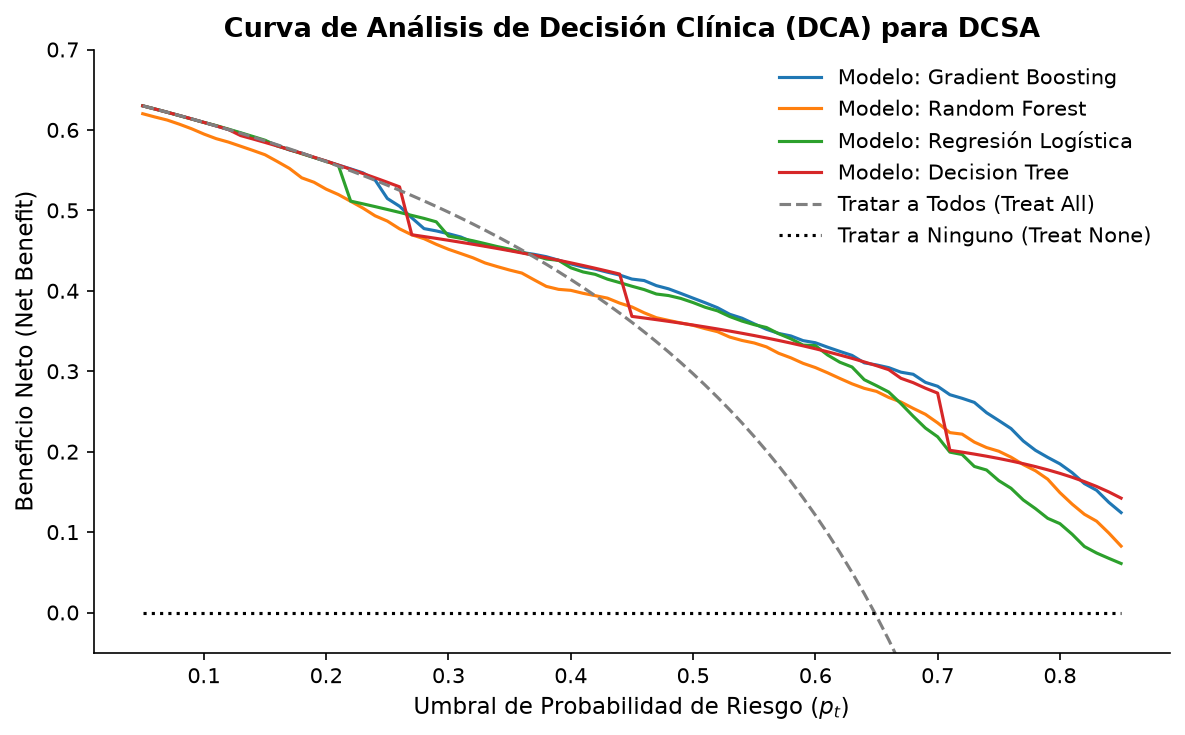

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

thresholds = np.linspace(0.05, 0.85, 81)
for mod_name in ['Gradient Boosting', 'Random Forest', 'Regresión Logística', 'Decision Tree']:
    thresh, nb_mod, nb_all = decision_curve_analysis(y_test, predicciones_prob[mod_name], thresholds)
    ax.plot(thresh, nb_mod, label=f'Modelo: {mod_name}')

ax.plot(thresh, nb_all, label='Tratar a Todos (Treat All)', linestyle='--', color='gray')
ax.plot(thresh, np.zeros_like(thresh), label='Tratar a Ninguno (Treat None)', linestyle=':', color='black')

ax.set_xlabel('Umbral de Probabilidad de Riesgo ($p_t$)')
ax.set_ylabel('Beneficio Neto (Net Benefit)')
ax.set_title('Curva de Análisis de Decisión Clínica (DCA) para DCSA')
ax.set_ylim(-0.05, 0.7)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(OUT_FIG / 'dca_dengue_dcsa.png')
plt.show()

## 5. Análisis Complementario e Integración con Evidencia Externa (Namaganda et al., 2026)

A partir de la revisión del estudio publicado por **Namaganda et al. (2026)** en *Frontiers in Artificial Intelligence* (*Predicting HIV viral non-suppression in Uganda: development and validation of machine learning and risk stratification models using routine EMR data*), se extraen valiosos aprendizajes metodológicos aplicables a la estratificación de riesgo en Dengue (DCSA):

### Comparación de Hallazgos Clave:

| Dimensión | Estudio Dengue Bucaramanga (DCSA) | Estudio Namaganda et al. (2026) | Lección Aplicada al Cuadro Clínico |
|---|---|---|---|
| **Tamaño de muestra / Cohorte** | 12,713 casos de DCSA (64.8% hospitalizados) | 33,384 pacientes VIH (6.4% no supresión) | El desbalance moderado (Dengue) vs severo (VIH) exige evaluar el **PR-AUC** como métrica principal para evitar optimismo en modelos predictivos. |
| **Prevalencia / Target** | Alta prevalencia del target (64.8%) | Baja prevalencia del target (6.4%) | Mientras que en VIH se evalúa la no supresión viral baja, en Dengue DCSA el reto es discriminar el **35.2% ambulatorio** para evitar ingresos innecesarios. |
| **Métricas Evaluadas** | F1-Score, PR-AUC, ROC-AUC, Brier Score, Balanced Acc. | PR-AUC (Principal), ROC-AUC, Brier Score, DCA | El **Brier Score** confirma la calibración de las probabilidades para tomar decisiones de triaje seguras. |
| **Estrategia de Capacidad** | *Capacity-First* (Top 5%/10%) y *Screening-First* (Sens ≥ 95%) | *Capacity-First* (Top 5%) logró ~5x enriquecimiento | En Dengue DCSA, un umbral de capacidad permite derivar con prioridad crítica a los pacientes con mayor riesgo de deterioro grave. |
| **Explicabilidad e Inferencia** | Signos de Alarma (Dolor abd., Vómito) y Variables Demográficas | Modelos Tree-based + SHAP + Regresión Elastic Net | La interpretabilidad basada en árboles y coeficientes confirma la validez biológica de las reglas clínicas. |

### Conclusiones Metodológicas:
1. **Calibración y Brier Score:** La evaluación de la Brier Score garantiza que las probabilidades estimadas por algoritmos como Gradient Boosting y Random Forest reflejen el riesgo real del paciente.
2. **Alineación con la Toma de Decisiones Médicas:** Integrar métricas de Decisión Clínica (DCA) y flexibilidad en el umbral (*Screening* vs. *Capacity*) transforma los modelos numéricos en herramientas operativas útiles para servicios de urgencias durante brotes epidémicos.